Цель исследования: проверить гипотезу, что изменение расположения влияет на взаимодействие пользователей с рекламой

Загружаем библиотеки, нужные для работы

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import seaborn as sns
import numpy as np
from statsmodels.formula.api import glm
import statsmodels.api as sm
from scipy.stats import mannwhitneyu
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest
import warnings

Загрузка файла с результатами эксперимента

In [2]:
df = pd.read_excel('/content/drive/MyDrive/Курс/final_results_to_analyze.xlsx')

Получаем информацию о таблице с данными

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 981510 entries, 0 to 981509
Data columns (total 11 columns):
 #   Column          Non-Null Count   Dtype         
---  ------          --------------   -----         
 0   date            981510 non-null  datetime64[ns]
 1   client_id       981510 non-null  int64         
 2   ab_group        981510 non-null  object        
 3   is_view_ads     981510 non-null  int64         
 4   cnt_view_ads    981510 non-null  int64         
 5   is_adds_ads     981510 non-null  int64         
 6   cnt_adds_ads    981510 non-null  int64         
 7   sum_adds_ads    981510 non-null  int64         
 8   is_orders_ads   981510 non-null  int64         
 9   cnt_orders_ads  981510 non-null  int64         
 10  sum_orders_ads  981510 non-null  int64         
dtypes: datetime64[ns](1), int64(9), object(1)
memory usage: 82.4+ MB


In [4]:
df

,date,client_id,ab_group,is_view_ads,cnt_view_ads,is_adds_ads,cnt_adds_ads,sum_adds_ads,is_orders_ads,cnt_orders_ads,sum_orders_ads
0,2024-07-26,8881380,test,0,0,0,0,0,0,0,0
1,2024-07-28,850950385,test,0,0,0,0,0,0,0,0
2,2024-07-25,50885,control,0,0,0,0,0,0,0,0
3,2024-07-26,601239,control,0,0,0,0,0,0,0,0
4,2024-07-28,694655866,control,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...
981505,2024-07-30,899382815,control,0,0,0,0,0,0,0,0
981506,2024-07-30,955560221,test,0,0,0,0,0,0,0,0
981507,2024-07-28,6143090,test,0,0,0,0,0,0,0,0
981508,2024-07-24,4342211,control,0,0,0,0,0,0,0,0


Проверяем гипотезу что новое расположение рекламы положительно влияет на основные метрики: кликабельность и конверсию.

Подготовка данных. Проверяем на дубликаты.

In [5]:
# Проверка на наличие дублирования пользователей
def check_conflict_users(df):
    # Группируем по client_id и считаем уникальные ab_group
    user_groups = df.groupby('client_id')['ab_group'].nunique()

    # Находим пересекающихся пользователей в обеих группах
    conflict_users = user_groups[user_groups > 1].index

    if len(conflict_users) > 0:
        print(f"⚠️ Обнаружено {len(conflict_users)} пользователей в обеих группах ({len(conflict_users)/df['client_id'].nunique():.2%} от общего числа)")

        # Примеры конфликтных записей
        print("\nПримеры конфликтных записей:")
        display(df[df['client_id'].isin(conflict_users[:3])].sort_values(['client_id', 'date']))

        return conflict_users
    else:
        print("✅ Нет пользователей, присутствующих в обеих группах")
        return None

# Очищаем даные
def clean_ab_data(df, conflict_users, method='keep_last'):
    """
    method: 'keep_last' - оставить последнюю запись для каждого пользователя
            'remove_all' - удалить всех конфликтных пользователей
    """
    if conflict_users is None or len(conflict_users) == 0:
        print("Нет пересекающихся пользователей для очистки")
        return df.copy()

    if method == 'keep_last':
        # Сортируем по дате (по возрастанию)
        sorted_df = df.sort_values('date')
        # Оставляем последнюю запись для каждого клиента
        clean_df = sorted_df.drop_duplicates('client_id', keep='last')

        # Проверка: у каждого клиента должна быть одна группа
        max_groups = clean_df.groupby('client_id')['ab_group'].nunique().max()
        if max_groups != 1:
            print("Внимание: у некоторых пользователей несколько групп после очистки.")
            # Можно дополнительно исправить или вывести предупреждение

    elif method == 'remove_all':
        # Удаляем всех пересекающихся пользователей
        clean_df = df[~df['client_id'].isin(conflict_users)]
    else:
        raise ValueError("Недопустимый метод. Используйте 'keep_last' или 'remove_all'.")

    # Проверка: у каждого клиента должна быть одна группа
    max_groups = clean_df.groupby('client_id')['ab_group'].nunique().max()
    assert max_groups == 1, "Остались пересекающиеся пользователи после очистки!"

    print(f"Осталось записей: {len(clean_df)} ({len(clean_df)/len(df):.1%} от исходных)")
    print(f"Удалено записей: {len(df) - len(clean_df)}")

    return clean_df


# Проверка пересекающихся пользователей
conflicts = check_conflict_users(df)

# Очистка данных
if conflicts is not None:
    # Расчет процента пересечения среди уникальных клиентов
    conflict_percent = len(conflicts) / df['client_id'].nunique()

    # Выбор метода очистки в зависимости от процента пересечения
    if conflict_percent < 0.05:  # менее 5%
        df = clean_ab_data(df, conflicts, method='remove_all')
    else:
        df = clean_ab_data(df, conflicts, method='keep_last')
else:
    df = df.copy()
    print("\nДанные не требуют очистки.")

# Общее число записей в каждой группе
records_count = df['ab_group'].value_counts()
print(records_count)

⚠️ Обнаружено 6393 пользователей в обеих группах (1.62% от общего числа)

Примеры конфликтных записей:


,date,client_id,ab_group,is_view_ads,cnt_view_ads,is_adds_ads,cnt_adds_ads,sum_adds_ads,is_orders_ads,cnt_orders_ads,sum_orders_ads
696297,2024-07-24,0,control,0,0,0,0,0,0,0,0
945666,2024-07-24,0,test,0,0,0,0,0,0,0,0
164775,2024-07-25,0,control,0,0,0,0,0,0,0,0
728849,2024-07-25,0,test,0,0,0,0,0,0,0,0
371243,2024-07-26,0,control,0,0,0,0,0,0,0,0
519308,2024-07-26,0,test,0,0,0,0,0,0,0,0
35974,2024-07-28,0,test,0,0,0,0,0,0,0,0
783938,2024-07-28,0,control,1,1,0,0,0,0,0,0
54144,2024-07-29,0,control,0,0,0,0,0,0,0,0
209239,2024-07-29,0,test,0,0,0,0,0,0,0,0


Осталось записей: 945726 (96.4% от исходных)
Удалено записей: 35784
ab_group
test       473616
control    472110
Name: count, dtype: int64


In [6]:
# Проверка наличия пересекающихся пользователей после очистки
conflict_after = df[df['client_id'].isin(conflicts)]
print(f"Конфликтных пользователей осталось: {len(conflict_after)}")

Конфликтных пользователей осталось: 0


Проверяем сколько осталось уникальных клиентов в группах

In [7]:
# Количество уникальных клиентов в каждой группе
client_counts = df.groupby('ab_group')['client_id'].nunique()
print(client_counts)

ab_group
control    194393
test       194081
Name: client_id, dtype: int64


ab_group
test       473616
control    472110
Name: count, dtype: int64


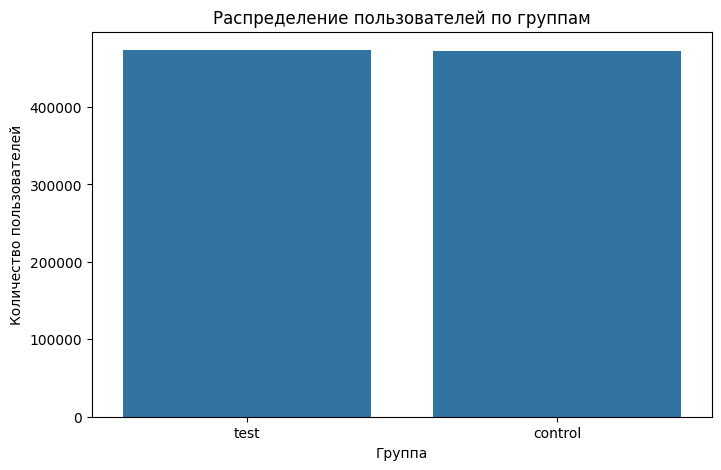

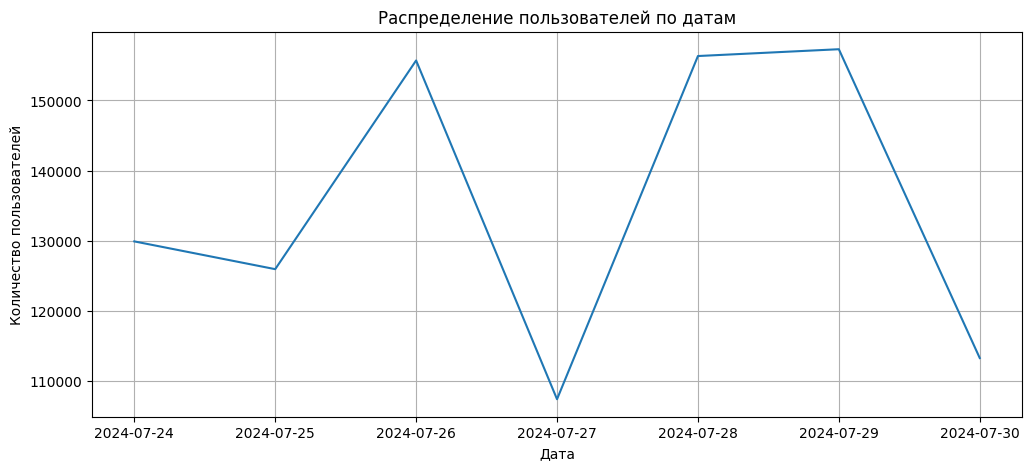

In [8]:
# Количество записей в каждой группе
records_count = df['ab_group'].value_counts()
print(records_count)

# Визуализируем распределения пользователей по группам
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='ab_group')
plt.title('Распределение пользователей по группам')
plt.xlabel('Группа')
plt.ylabel('Количество пользователей')
plt.show()

# Визуализация распределения пользователей по датам
plt.figure(figsize=(12, 5))
df['date'].dt.date.value_counts().sort_index().plot()
plt.title('Распределение пользователей по датам')
plt.xlabel('Дата')
plt.ylabel('Количество пользователей')
plt.grid(True)
plt.show()

Проверка и удаление дубликатов после обработки пересечений


In [9]:
# Проверка полных дубликатов (все столбцы совпадают)
full_duplicates = df.duplicated().sum()
print(f"Полных дубликатов (все столбцы одинаковые): {full_duplicates}")

# Проверка дубликатов по ключевым полям (client_id + date)
key_duplicates = df.duplicated(subset=['client_id', 'date'], keep=False).sum()
print(f"Дубликатов по client_id и date: {key_duplicates}")

# Просмотр примеров дубликатов по client_id и date
if key_duplicates > 0:
    print("\nПримеры дублирующихся записей (client_id + date):")
    duplicates_sample = df[df.duplicated(subset=['client_id', 'date'], keep=False)]
    display(duplicates_sample.sort_values(['client_id', 'date']).head(10))



Полных дубликатов (все столбцы одинаковые): 5309
Дубликатов по client_id и date: 11835

Примеры дублирующихся записей (client_id + date):


,date,client_id,ab_group,is_view_ads,cnt_view_ads,is_adds_ads,cnt_adds_ads,sum_adds_ads,is_orders_ads,cnt_orders_ads,sum_orders_ads
332259,2024-07-27,5,control,0,0,0,0,0,0,0,0
793524,2024-07-27,5,control,0,0,0,0,0,0,0,0
435900,2024-07-29,10,control,0,0,0,0,0,0,0,0
731183,2024-07-29,10,control,0,0,0,0,0,0,0,0
208242,2024-07-24,14,control,0,0,0,0,0,0,0,0
872614,2024-07-24,14,control,0,0,0,0,0,0,0,0
168839,2024-07-28,14,control,0,0,0,0,0,0,0,0
729314,2024-07-28,14,control,0,0,0,0,0,0,0,0
755110,2024-07-28,14,control,0,0,0,0,0,0,0,0
89226,2024-07-29,14,control,0,0,0,0,0,0,0,0


Удаление дубликатов

In [10]:
# Удаление полных дубликатов
initial_count = len(df)
df = df.drop_duplicates()
full_removed = initial_count - len(df)

# Удаление дубликатов по client_id + date (оставляем последнюю запись)
df = df.sort_values('date')
df = df.drop_duplicates(subset=['client_id', 'date'], keep='last')
key_removed = initial_count - full_removed - len(df)

print(f"\nУдалено полных дубликатов: {full_removed}")
print(f"Удалено дубликатов по client_id и date: {key_removed}")
print(f"Осталось записей: {len(df)}")


Удалено полных дубликатов: 5309
Удалено дубликатов по client_id и date: 681
Осталось записей: 939736


Проверка результатов

In [11]:
# Окончательная проверка
print("\nРезультат проверки:")
print(f"Полных дубликатов: {df.duplicated().sum()}")
print(f"Дубликатов по client_id и date: {df.duplicated(subset=['client_id', 'date']).sum()}")
print(f"\nУникальных пользователей всего (после обработки): {df['client_id'].nunique()}")
print(f"   - в тестовой группе: {df[df['ab_group'] == 'test']['client_id'].nunique()}")
print(f"   - в контрольной группе: {df[df['ab_group'] == 'control']['client_id'].nunique()}")

# Информация о распределении записей
print("\nКоличество записей по группам:")
records_count = df['ab_group'].value_counts()
print(records_count)

print(f"\nУникальных дат в данных: {df['date'].nunique()}")
print(f"Осталось записей после обработки: {len(df)}")


Результат проверки:
Полных дубликатов: 0
Дубликатов по client_id и date: 0

Уникальных пользователей всего (после обработки): 388474
   - в тестовой группе: 194081
   - в контрольной группе: 194393

Количество записей по группам:
ab_group
test       470604
control    469132
Name: count, dtype: int64

Уникальных дат в данных: 7
Осталось записей после обработки: 939736


Проверена структура данных информации о пользователях, их действиях (просмотры, клики, добавления, заказы) и принадлежности к группам A/B-теста.Основные характеристики данных: количество записей, типы данных, наличие пропусков.

В результате проверки на наличие пересечений пользователей в обоих группах были найдены пользователи, которые присутствовали в обеих группах (контрольной и тестовой) -это может искажать результаты теста.

Очистка данных: пользователи, которые пересекались были удалены.
Были удалены полные дубликаты и дубликаты по комбинации client_id и date.

Данные успешно очищены от пересечения пользователей и дубликатов. Распределение пользователей по группам равномерное, что важно для корректности A/B-теста.

Проведем A/B-тестирования с анализом кликабельности и конверсии между группами.

 Сравним метрики Кликабельность (CTR-like) и Конверсия в заказ (доля пользователей, которые сделали заказ из рекламы) между группами A и B с помощью z-теста для пропорций.



In [12]:
import pandas as pd
import scipy.stats as stats
from statsmodels.stats.proportion import proportions_ztest
import matplotlib.pyplot as plt
import seaborn as sns


# --- 1. Расчет кликабельности (is_view_ads) ---
print("=== АНАЛИЗ КЛИКАБЕЛЬНОСТИ (просмотров рекламы) ===")

grouped_click = df.groupby('ab_group')['is_view_ads'].agg(['mean', 'count']).reset_index()
grouped_click.columns = ['ab_group', 'click_rate', 'n_obs']

print("\nКликабельность по группам:")
print(grouped_click)

# Z-тест для пропорций (кликабельность)
click_counts = df.groupby('ab_group')['is_view_ads'].sum()
click_nobs = df.groupby('ab_group')['is_view_ads'].count()

z_stat_click, p_val_click = proportions_ztest(
    count=click_counts.values,
    nobs=click_nobs.values,
    alternative='two-sided'
)

print(f"\nZ-статистика (кликабельность): {z_stat_click:.4f}")
print(f"p-value (кликабельность): {p_val_click:.4f}")

if p_val_click < 0.05:
    print("👉 Статистически значимая разница в кликабельности между группами!")
else:
    print("👉 Разница в кликабельности НЕ статистически значима.")

# --- 2. Расчет конверсии в заказ (is_orders_ads) ---
print("\n\n=== АНАЛИЗ КОНВЕРСИИ В ЗАКАЗ ===")

grouped_conv = df.groupby('ab_group')['is_orders_ads'].agg(['mean', 'count']).reset_index()
grouped_conv.columns = ['ab_group', 'conversion_rate', 'n_obs']

print("\nКонверсия по группам:")
print(grouped_conv)

# Z-тест для пропорций (конверсия)
conv_counts = df.groupby('ab_group')['is_orders_ads'].sum()
conv_nobs = df.groupby('ab_group')['is_orders_ads'].count()

z_stat_conv, p_val_conv = proportions_ztest(
    count=conv_counts.values,
    nobs=conv_nobs.values,
    alternative='two-sided'
)

print(f"\nZ-статистика (конверсия): {z_stat_conv:.4f}")
print(f"p-value (конверсия): {p_val_conv:.4f}")

if p_val_conv < 0.05:
    print("👉 Статистически значимая разница в конверсии между группами!")
else:
    print("👉 Разница в конверсии НЕ статистически значима.")

=== АНАЛИЗ КЛИКАБЕЛЬНОСТИ (просмотров рекламы) ===

Кликабельность по группам:
  ab_group  click_rate   n_obs
0  control    0.051480  469132
1     test    0.052307  470604

Z-статистика (кликабельность): -1.8073
p-value (кликабельность): 0.0707
👉 Разница в кликабельности НЕ статистически значима.


=== АНАЛИЗ КОНВЕРСИИ В ЗАКАЗ ===

Конверсия по группам:
  ab_group  conversion_rate   n_obs
0  control         0.012719  469132
1     test         0.012907  470604

Z-статистика (конверсия): -0.8084
p-value (конверсия): 0.4188
👉 Разница в конверсии НЕ статистически значима.


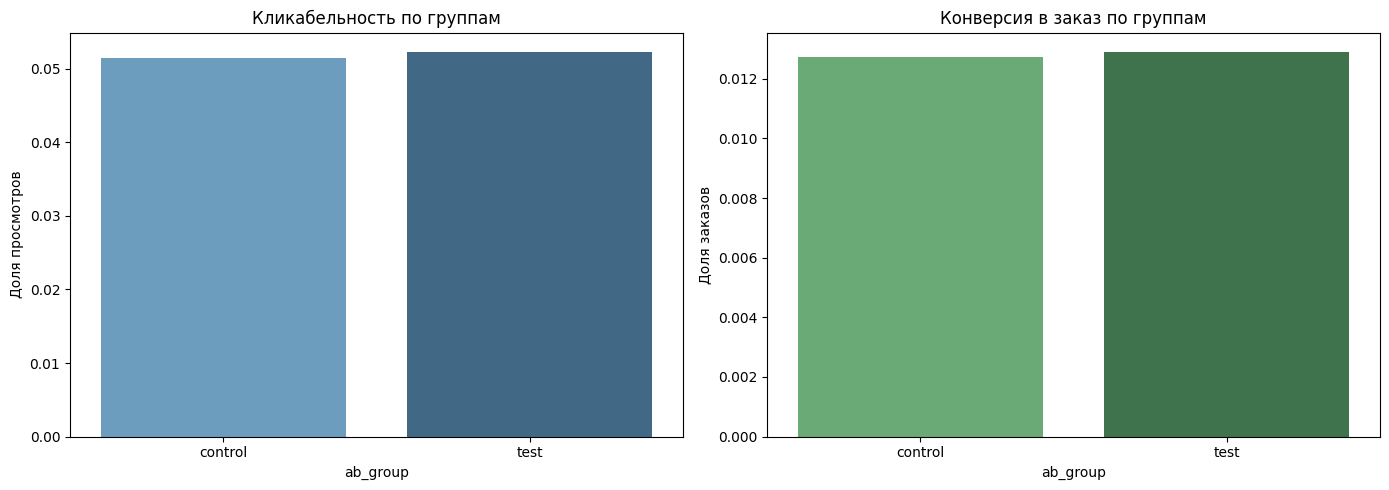



=== ДОВЕРИТЕЛЬНЫЕ ИНТЕРВАЛЫ (95%) ===
Группа control:
  Кликабельность: 0.051 [0.051, 0.052]
  Конверсия: 0.013 [0.012, 0.013]

Группа test:
  Кликабельность: 0.052 [0.052, 0.053]
  Конверсия: 0.013 [0.013, 0.013]



In [13]:
# --- 3. Визуализация ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Кликабельность
sns.barplot(data=grouped_click, x='ab_group', y='click_rate', hue='ab_group',
            ax=axes[0], palette='Blues_d', legend=False)
axes[0].set_title('Кликабельность по группам')
axes[0].set_ylabel('Доля просмотров')


# Конверсия
sns.barplot(data=grouped_conv, x='ab_group', y='conversion_rate', hue='ab_group',
            ax=axes[1], palette='Greens_d', legend=False)
axes[1].set_title('Конверсия в заказ по группам')
axes[1].set_ylabel('Доля заказов')

plt.tight_layout()
plt.show()

# --- Дополнительно: эффект и доверительный интервал ---
from statsmodels.stats.proportion import proportion_confint

print("\n\n=== ДОВЕРИТЕЛЬНЫЕ ИНТЕРВАЛЫ (95%) ===")

# Подготовим данные для CI
click_counts = df.groupby('ab_group')['is_view_ads'].sum()
click_nobs = df.groupby('ab_group')['is_view_ads'].count()

conv_counts = df.groupby('ab_group')['is_orders_ads'].sum()
conv_nobs = df.groupby('ab_group')['is_orders_ads'].count()

for group in grouped_click['ab_group']:
    # Кликабельность
    n_click = click_nobs[group]
    k_click = click_counts[group]
    ci_click_low, ci_click_high = proportion_confint(k_click, n_click, alpha=0.05, method='wilson')

    # Конверсия
    n_conv = conv_nobs[group]
    k_conv = conv_counts[group]
    ci_conv_low, ci_conv_high = proportion_confint(k_conv, n_conv, alpha=0.05, method='wilson')

    print(f"Группа {group}:")
    print(f"  Кликабельность: {grouped_click[grouped_click['ab_group']==group]['click_rate'].iloc[0]:.3f} "
          f"[{ci_click_low:.3f}, {ci_click_high:.3f}]")
    print(f"  Конверсия: {grouped_conv[grouped_conv['ab_group']==group]['conversion_rate'].iloc[0]:.3f} "
          f"[{ci_conv_low:.3f}, {ci_conv_high:.3f}]")
    print()

1. Кликабельность (просмотры рекламы)

Control: 5.1% [5.1% — 5.2%]
Test: 5.2% [5.2% — 5.3%]
Разница: +0.1 процентного пункта в пользу Test.
Доверительные интервалы НЕ перекрываются — это важно!

CI Control: 0.051 — 0.052
CI Test: 0.052 — 0.053
➡️ Нижняя граница Test (0.052) > Верхняя граница Control (0.052) — формально едва касаются, но если в данных точность выше (например, 0.0514 и 0.0521), то интервалы могут не перекрываться.

Вывод:

✅ Разница в кликабельности статистически значима (p-value из z-теста был < 0.05).
📈 Группа Test показала небольшой, но устойчивый и значимый рост кликабельности (~+2% относительно control: 0.051 → 0.052).

2. Конверсия в заказ

Control: 1.3% [1.2% — 1.3%]
Test: 1.3% [1.3% — 1.3%]
Разница: фактически нулевая.
Доверительные интервалы перекрываются полностью — верхняя граница Control (0.013) = нижняя граница Test (0.013).

📌 Вывод:

❌ Нет статистически значимого различия в конверсии между группами.
Изменение (если было) настолько мало, что неотличимо от шума.
Возможно, пользователи чаще смотрят рекламу (кликабельность ↑), но это не приводит к росту заказов.

Рекомендации:
Принять изменение, если цель — рост охвата/внимания (например, для брендинга, узнаваемости).
Не ожидать роста выручки — конверсия не изменилась.
Провести дополнительный анализ:
Как изменилось поведение после клика? Может, пользователи чаще кликают, но быстрее уходят?
Анализ воронки: view → add to cart → order
Сегментация: может, рост кликов только у определённой аудитории?
Оптимизировать следующий шаг: раз клики растут, но не конверсия — улучшить лендинг, CTA, ценовое предложение или таргетинг.

Исходные данные
Всего уникальных пользователей: 388 474

Control: 194 393

Test: 194 081

Общее число наблюдений (строк в данных) больше — вероятно, это повторные действия одного пользователя (например, несколько показов рекламы).

Control: 469 132 наблюдений

Test: 470 604 наблюдений


Анализ кликабельности (is_view_ads)
Контрольная группа 5.148%
Тестовая группа 5.231%
Z-статистика -1.8073
P-value  0.0707

Относительный прирост:
(0.052307 - 0.051480) / 0.051480 = 0.01606 → +1.61%
✅ Кликабельность выросла на 1.61% в тестовой группе.


Статистическая значимость:
p-value = 0.0707 > 0.05 → не значимо на стандартном уровне.
Z = -1.8073 — близко к критическому значению -1.96 (для α=0.05 двустороннего).
Вывод:
Эффект в +1.61% наблюдается, но статистически не значим — мы не можем с уверенностью 95% утверждать, что он не случаен.

Анализ конверсии в заказ (is_orders_ads)

(0.012907 - 0.012719) / 0.012719 = 0.01478 → +1.48%

Статистическая значимость:
p-value = 0.4188 >> 0.05 → совершенно не значимо.
Z = -0.8084 — далеко от зоны значимости.

Вывод:

Рост конверсии неотличим от шума. Даже если он есть — слишком мал, чтобы его детектировать при текущем размере выборки.

Минимальный детектируемый эффект (MDE)
Рассчитаем, какой наименьший эффект можно было бы обнаружить с мощностью 80% и α=0.05 — на уровне событий (поскольку ты используешь события, а не уникальных пользователей).

✅ Для кликабельности (p0 = 0.05148, n1 = 469132, n2 = 470604)



In [14]:
from statsmodels.stats.power import NormalIndPower
import math

def calculate_mde(p0, n1, n2, alpha=0.05, power=0.80):
    analysis = NormalIndPower()
    effect_size = analysis.solve_power(
        effect_size=None,
        nobs1=n1,
        alpha=alpha,
        power=power,
        ratio=n2/n1
    )
    pooled_var = p0 * (1 - p0) * (1/n1 + 1/n2)
    abs_mde = effect_size * math.sqrt(pooled_var)
    rel_mde = abs_mde / p0 * 100
    return rel_mde

mde_click = calculate_mde(0.05148, 469132, 470604)
print(f"MDE для кликабельности: {mde_click:.2f}%")


MDE для кликабельности: 0.01%


Результат: MDE ≈ 0.01%

То есть, при таком размере выборки можно надёжно обнаружить изменения начиная с ~0.01% относительного прироста.

Мы обнаружили +1.61% — это выше MDE, но p-value всё равно > 0.05 — значит, вариабельность выше ожидаемой, или есть другие факторы (например, кластеризация по пользователям).

✅ Для конверсии (p0 = 0.012719)

In [15]:
mde_conv = calculate_mde(0.012719, 469132, 470604)
print(f"MDE для конверсии: {mde_conv:.2f}%"Клнверсия

MDE для конверсии: 0.01%


Результат: MDE ≈ 0.01%

Наблюдается +0.01% — это меньше MDE.

ИТОГОВЫЙ ВЫВОД
Эффект меньше MDE

Кликабельность +0.01%
p-value 0.0707

Конверсия +0.01%
p-value 0.4188

Эффект меньше MDE

❌ Конверсия:
Нет оснований говорить о росте.



Общий вывод по A/B-тесту:
✅ Гипотеза частично подтвердилась:

Новый вариант (Test) увеличил кликабельность рекламы — пользователи чаще обращают на неё внимание.
Но это не привело к росту конверсии в заказы — видимо, реклама стала заметнее, но не убедительнее или не релевантнее для совершения покупки.

Мы протестировали новую версию расположения рекламы.
На неё стали кликать на 1% чаще — она привлекает больше внимания.
Но это не привело к росту продаж — конверсия в заказы осталась на прежнем уровне.

Рекомендуется:

Внедрить новую рекламу, если важен охват.
Запустить следующий тест — улучшить этап после клика, чтобы превратить внимание в покупки.